# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

In [ ]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

In [ ]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur en Q31 (32 bits) pour éviter les débordements
        acc = np.int32(0)
        for k in range(M):
            acc += np.int32(state[k]) * np.int32(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
b_float = b_float / np.max(np.abs(b_float))  # normalisation pour rester dans [-1, 1]
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t)
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

In [ ]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

In [ ]:
# Table de sinus Q15 pour 360 degrés (ou 2*pi radians)
# En pratique, la table est stockée dans la mémoire du microcontrôleur.
def sin_q15(angle_q15):
    """Simule arm_sin_q15 : angle en Q15 (0 correspond à 0 rad, 32767 correspond à 2*pi)."""
    # angle_q15 est un entier int16 entre 0 et 32767 représentant 0 à 2*pi
    # On utilise une interpolation linéaire sur une table de 256 points
    n_points = 256
    table = np.sin(2*np.pi * np.arange(n_points) / n_points)
    # Convertir angle_q15 en index 0..n_points-1
    idx = (angle_q15 * n_points) // 32768
    idx = np.clip(idx, 0, n_points-1)
    # Interpolation linéaire
    frac = (angle_q15 * n_points) % 32768 / 32768.0
    val = (1-frac) * table[idx] + frac * table[(idx+1) % n_points]
    return float_to_q15(val)

# Test
angles = np.linspace(0, 2*np.pi, 100)
sin_float = np.sin(angles)
sin_q15_vals = np.array([sin_q15(float_to_q15(angle/(2*np.pi))) for angle in angles])
sin_reconst = q15_to_float(sin_q15_vals)

plt.plot(angles, sin_float, label='sin flottant')
plt.plot(angles, sin_reconst, '--', label='sin Q15 (table)')
plt.legend()
plt.grid()
plt.show()

# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

In [ ]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
x_float = np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t) + 0.1*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_float = b_float / np.max(np.abs(b_float))
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

# Exercice 1 – Filtre RII Butterworth en Q15 (structure directe II)

**Problèmes à résoudre pour passer en Q15** :
- Q15 ne représente que [-1, 1[ : les coefficients de `a` (jusqu'à 2,37 pour l'ordre 4) sont **normalisés** par 2^s puis compensés par un décalage dans l'accumulateur (comme le `postShift` de CMSIS). `a[0] = 1` est donc implicite (il ne peut pas valoir 32767).
- En directe II, l'état w[n] = x[n] − Σ aₖ·w[n−k] a un gain de **≈ 14** (max de 1/A(z)) : il déborde. L'entrée est donc **pré-atténuée de 2^-g** (g = 4) et la sortie est remise à l'échelle.
- Accumulateur 32 bits : produits Q15×Q15 = Q30, somme en Q30, puis arrondi et retour en Q15 avec saturation.

**Question 5 – ordre trop élevé en Q15** : les coefficients de `a` grandissent très vite avec l'ordre (13 pour l'ordre 8, 77 pour l'ordre 12) ; il faut un décalage s de plus en plus grand donc un pas de quantification de plus en plus grossier. Les pôles, regroupés près du cercle unité, se déplacent beaucoup : le filtre devient **instable** (ordre ≥ 10 pour fc = 100 Hz, ordre ≥ 6 pour fc = 20 Hz). Solutions : **cascade de biquads** (`arm_biquad_cascade_df1_q15`), accumulateurs 64 bits, ou Q31.

b (float) : [0.00482 0.0193  0.02895 0.0193  0.00482]
a (float) : [ 1.      -2.36951  2.31399 -1.05467  0.18738]
b_q : [158 632 949 632 158] | décalage sb = 0
a_q : [  8192 -19411  18956  -8640   1535] | décalage sa = 2 (a0 = 1 implicite)
Gain max de 1/A(z) = 13.94 -> pré-atténuation de l'entrée de 2^-4
Erreur max = 4.87e-04 | RMS = 1.86e-04 | SNR = 65.9 dB
Accumulateur max = 0.36 x 2^31  (<1 : tient dans 32 bits)
Sans pré-atténuation : erreur max = 0.64  (saturation de l'état)


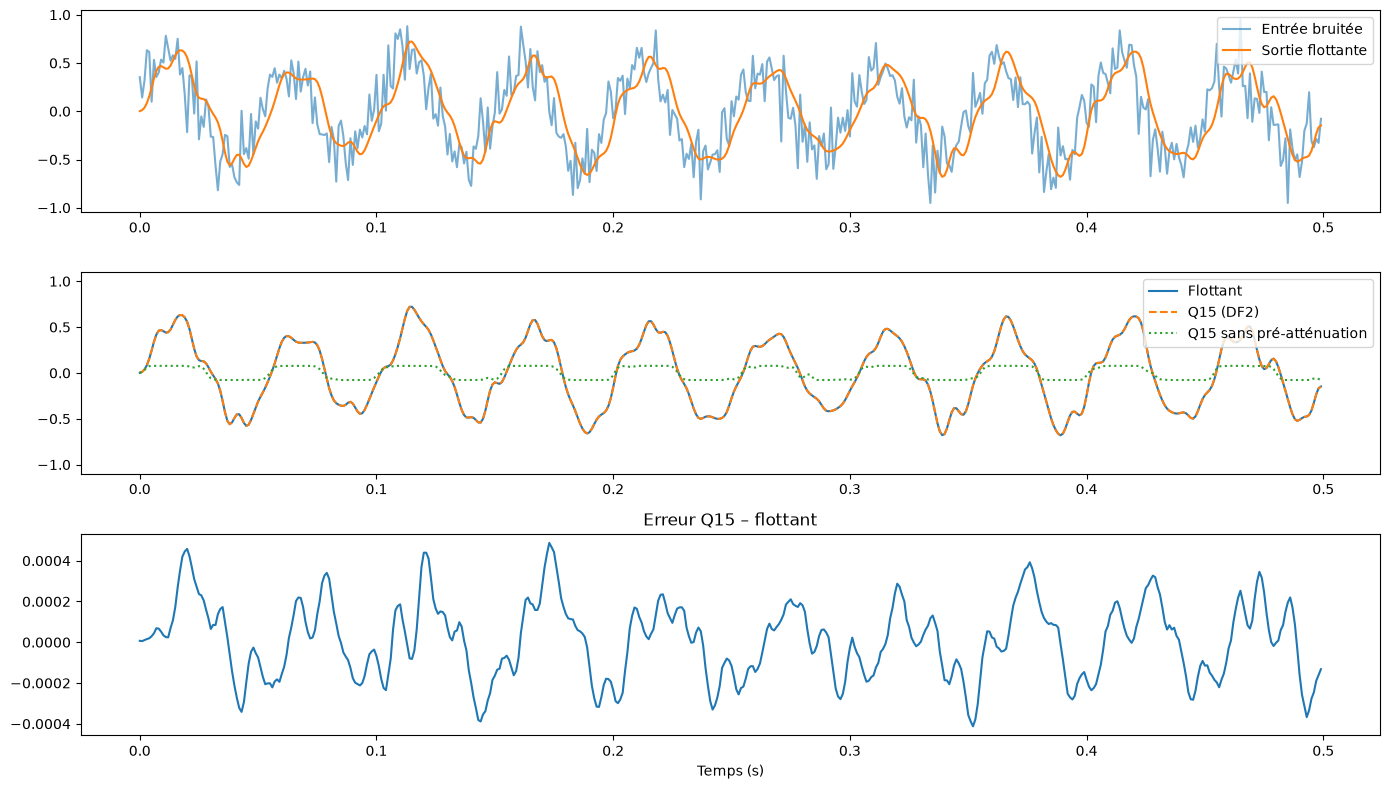


 fc (Hz)  ordre   max|a|  décal.  max|p| flottant  max|p| Q15  stable
     100      2     1.14       1           0.6425      0.6425    True
     100      4     2.37       2           0.7954      0.7953    True
     100      6     5.66       3           0.8579      0.8586    True
     100      8    13.46       4           0.8912      0.8923    True
     100     10    32.16       6           0.9119      1.0476   False
     100     12    77.29       7           0.9260      1.2227   False
      20      2     1.82       1           0.9150      0.9150    True
      20      4     5.07       3           0.9531      0.9978    True
      20      6    15.59       4           0.9681      1.1493   False
      20      8    50.34       6           0.9758      1.2987   False
      20     10   167.08       8           0.9806      1.7739   False
      20     12   564.74      10           0.9843      2.2968   False


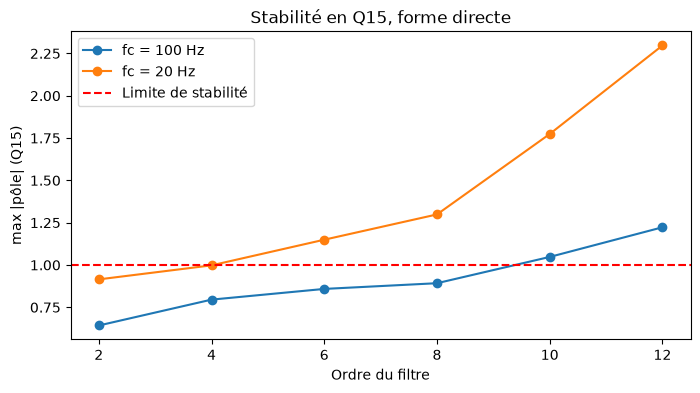

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import warnings; warnings.filterwarnings("ignore")

# ---------- Outils Q15 (convention CMSIS : x * 2^15, saturé à [-32768, 32767]) ----------
def float_to_q15(x):
    return np.clip(np.round(np.asarray(x, float) * 32768), -32768, 32767).astype(np.int16)

def q15_to_float(x_q):
    return np.asarray(x_q, dtype=np.float64) / 32768.0

def sat16(v):
    return max(-32768, min(32767, int(v)))

def shift_necessaire(c):
    """Plus petit s tel que max|c| / 2^s < 1 (décalage de normalisation)."""
    return max(0, int(np.floor(np.log2(np.max(np.abs(c))))) + 1)

# ---------- Filtre RII en Q15, structure directe II ----------
def iir_q15(x_q, b_q, a_q, sa=0, sb=0, g=0):
    """
    w[n] = x[n]/2^g - sum_k a_k w[n-k]      (accumulateur 32 bits en Q30)
    y[n] = 2^g * sum_k b_k w[n-k]
    a_q = Q15 de a/2^sa, b_q = Q15 de b/2^sb (a_q[0] correspond à a0=1, il est implicite).
    g : pré-atténuation de l'entrée (en bits) pour éviter le débordement de l'état w.
    """
    M, N = len(b_q) - 1, len(a_q) - 1
    w = [0] * (max(M, N) + 1)                   # w[k] = w[n-k] après mise à jour
    y = np.zeros(len(x_q), dtype=np.int16)
    acc_max = 0
    for n, xn in enumerate(x_q):
        xs = (int(xn) + ((1 << (g - 1)) if g else 0)) >> g
        acc = xs << 15                          # Q30
        for k in range(1, N + 1):
            acc -= (int(a_q[k]) * w[k - 1]) << sa
        acc_max = max(acc_max, abs(acc))
        w = [sat16((acc + (1 << 14)) >> 15)] + w[:-1]   # état en Q15, saturé
        acc2 = sum(int(b_q[k]) * w[k] for k in range(M + 1)) << (sb + g)
        acc_max = max(acc_max, abs(acc2))
        y[n] = sat16((acc2 + (1 << 14)) >> 15)
    return y, acc_max

def concevoir_q15(order, fc, fs):
    """Conception flottante + normalisation + quantification Q15."""
    b, a = signal.butter(order, fc, fs=fs)
    sb = shift_necessaire(b) if np.max(np.abs(b)) >= 1 else 0
    sa = shift_necessaire(a)
    b_q, a_q = float_to_q15(b / 2**sb), float_to_q15(a / 2**sa)
    g = int(np.ceil(np.log2(np.max(np.abs(signal.freqz([1], a, worN=4096)[1])))))
    return b, a, b_q, a_q, sb, sa, g

# ---------- 1) et 2) Conception Butterworth ordre 4, coefficients Q15 ----------
fs, fc, order = 1000, 100, 4
b, a, b_q, a_q, sb, sa, g = concevoir_q15(order, fc, fs)
print("b (float) :", b.round(5));  print("a (float) :", a.round(5))
print("b_q :", b_q, "| décalage sb =", sb)
print("a_q :", a_q, "| décalage sa =", sa, "(a0 = 1 implicite)")
print("Gain max de 1/A(z) =", np.max(np.abs(signal.freqz([1], a, worN=4096)[1])).round(2),
      "-> pré-atténuation de l'entrée de 2^-%d" % g)

# ---------- 4) Test sur un signal bruité ----------
np.random.seed(0)
t = np.arange(0, 0.5, 1/fs)
x = np.clip(0.5*np.sin(2*np.pi*20*t) + 0.2*np.random.randn(len(t)), -0.95, 0.95)
x_q = float_to_q15(x)

y_q, acc_max = iir_q15(x_q, b_q, a_q, sa, sb, g)
y_q15 = q15_to_float(y_q)
y_ref = signal.lfilter(b, a, q15_to_float(x_q))                  # référence flottante
y_sat, _ = iir_q15(x_q, b_q, a_q, sa, sb, 0)                      # sans pré-atténuation

err = y_q15 - y_ref
print(f"Erreur max = {np.max(np.abs(err)):.2e} | RMS = {np.sqrt(np.mean(err**2)):.2e} | "
      f"SNR = {20*np.log10(np.std(y_ref)/np.std(err)):.1f} dB")
print(f"Accumulateur max = {acc_max/2**31:.2f} x 2^31  (<1 : tient dans 32 bits)")
print(f"Sans pré-atténuation : erreur max = {np.max(np.abs(q15_to_float(y_sat) - y_ref)):.2f}  (saturation de l'état)")

plt.figure(figsize=(14, 8))
plt.subplot(3, 1, 1); plt.plot(t, x, alpha=0.6, label='Entrée bruitée'); plt.plot(t, y_ref, label='Sortie flottante'); plt.legend()
plt.subplot(3, 1, 2); plt.plot(t, y_ref, label='Flottant'); plt.plot(t, y_q15, '--', label='Q15 (DF2)')
plt.plot(t, q15_to_float(y_sat), ':', label='Q15 sans pré-atténuation'); plt.ylim(-1.1, 1.1); plt.legend()
plt.subplot(3, 1, 3); plt.plot(t, err); plt.title('Erreur Q15 – flottant'); plt.xlabel('Temps (s)')
plt.tight_layout(); plt.show()

# ---------- 5) Stabilité en fonction de l'ordre (coefficients Q15 de a) ----------
print(f"\n{'fc (Hz)':>8}{'ordre':>7}{'max|a|':>9}{'décal.':>8}{'max|p| flottant':>17}{'max|p| Q15':>12}{'stable':>8}")
resultats = {}
for fc_ in (100, 20):
    for o in (2, 4, 6, 8, 10, 12):
        aa = signal.butter(o, fc_, fs=fs)[1]
        s_a = shift_necessaire(aa)
        a_deq = q15_to_float(float_to_q15(aa / 2**s_a)) * 2**s_a      # coefficients après quantification
        p0, pq = np.max(np.abs(np.roots(aa))), np.max(np.abs(np.roots(a_deq)))
        resultats[(fc_, o)] = pq
        print(f"{fc_:>8}{o:>7}{np.max(np.abs(aa)):>9.2f}{s_a:>8}{p0:>17.4f}{pq:>12.4f}{str(pq < 1):>8}")

plt.figure(figsize=(8, 4))
for fc_ in (100, 20):
    plt.plot([2, 4, 6, 8, 10, 12], [resultats[(fc_, o)] for o in (2, 4, 6, 8, 10, 12)], 'o-', label=f'fc = {fc_} Hz')
plt.axhline(1, color='r', ls='--', label='Limite de stabilité')
plt.xlabel("Ordre du filtre"); plt.ylabel('max |pôle| (Q15)'); plt.legend(); plt.title('Stabilité en Q15, forme directe')
plt.show()

In [ ]:
# À compléter
def iir_q15(x_q, b_q, a_q):
    # a_q[0] doit être 1 en Q15 (c'est-à-dire 32767)
    # Implémenter la structure directe II en Q15
    pass

# Test


## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

# Exercice 2 – FFT en Q15 et fenêtrage

- Signal : 0,4·sin(2π·120t) + 0,4·sin(2π·130t), fs = 1000 Hz, N = 64.
- Résolution de Fourier : fs/N = **15,6 Hz**, supérieure à l'écart des deux sinusoïdes (10 Hz).
- FFT radix-2 écrite en entiers Q15 : produit complexe avec twiddles Q15, arrondi, et **décalage de 1 bit à chaque étage** (comme CMSIS) pour éviter le débordement ; la sortie vaut X/N.
- Fenêtre de Hamming convertie en Q15, appliquée par un produit Q15×Q15 avec arrondi.

Résolution de Fourier fs/N = 15.62 Hz  (écart des sinusoïdes : 10 Hz)
Erreur max FFT Q15 vs flottant : sans fenêtre = 0.0025 | Hamming = 0.0028

    N  fs/N (Hz)   creux rect.   creux Hamming
   64      15.62    non résolu      1 seul pic
   96      10.42      -22.0 dB        -14.7 dB
  128       7.81       -9.4 dB         -3.5 dB
  256       3.91      -14.0 dB        -10.5 dB
Rectangulaire : niveau à 200 Hz = -29.6 dB | à 300 Hz = -37.8 dB
Hamming       : niveau à 200 Hz = -50.4 dB | à 300 Hz = -54.3 dB


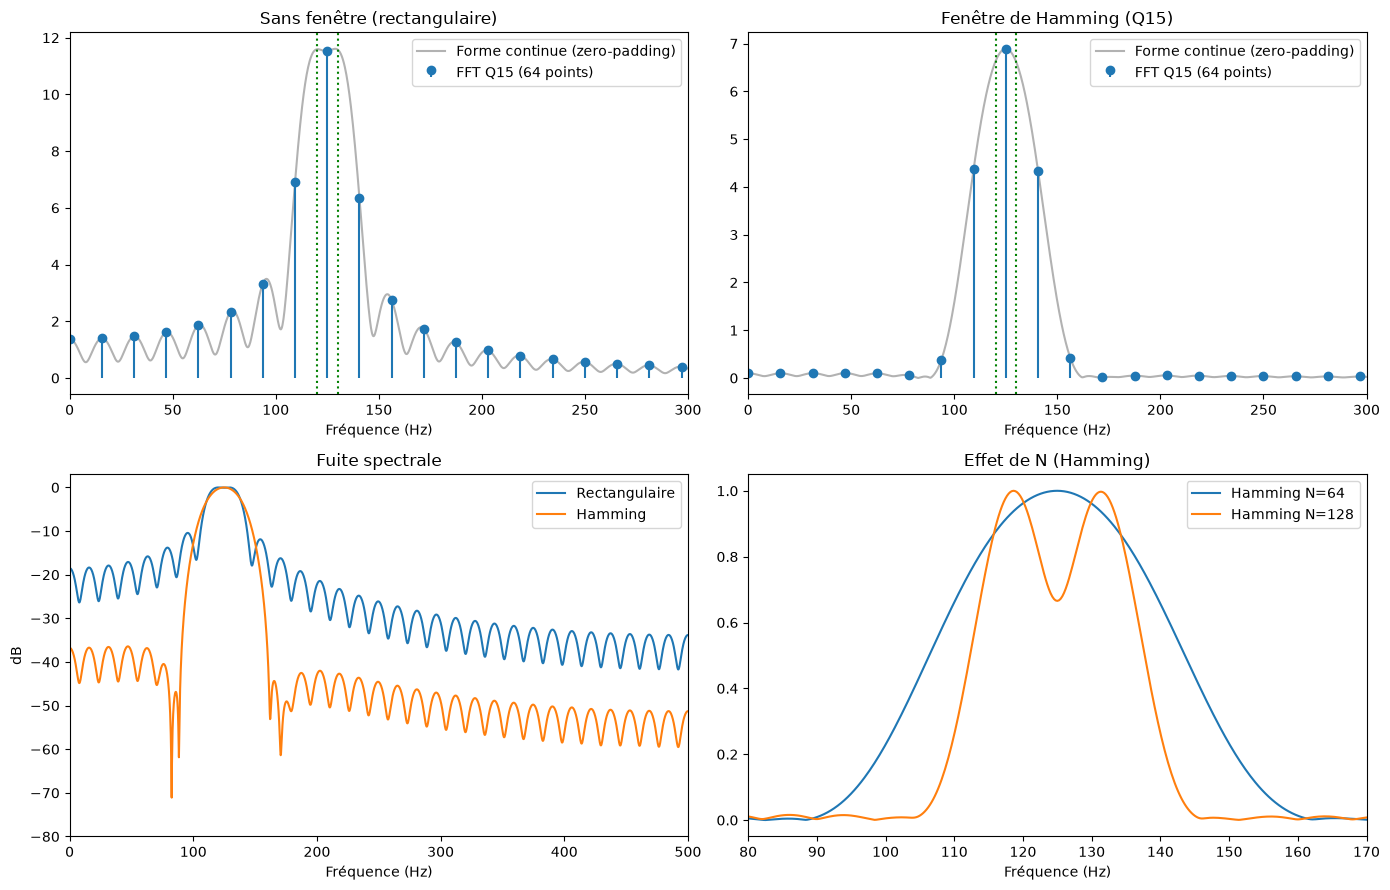

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# ---------- Outils Q15 ----------
def float_to_q15(x):
    return np.clip(np.round(np.asarray(x, float) * 32768), -32768, 32767).astype(np.int16)

def q15_to_float(x_q):
    return np.asarray(x_q, dtype=np.float64) / 32768.0

def mult_q15(a_q, b_q):
    """Produit Q15 x Q15 -> Q15 (accumulateur 32 bits, arrondi, saturation)."""
    p = (a_q.astype(np.int32) * b_q.astype(np.int32) + (1 << 14)) >> 15
    return np.clip(p, -32768, 32767).astype(np.int16)

# ---------- FFT radix-2 en Q15 (mise à l'échelle 1/2 par étage => sortie = X/N) ----------
def fft_q15(x_q):
    N = len(x_q); etages = int(np.log2(N))
    idx = np.array([int(format(i, f'0{etages}b')[::-1], 2) for i in range(N)])   # bit-reversal
    re, im = x_q.astype(np.int32)[idx], np.zeros(N, dtype=np.int32)
    tw = np.exp(-2j * np.pi * np.arange(N // 2) / N)                              # twiddles en Q15
    wr, wi = float_to_q15(tw.real).astype(np.int32), float_to_q15(tw.imag).astype(np.int32)
    taille = 2
    for _ in range(etages):
        demi = taille // 2
        for debut in range(0, N, taille):
            for k in range(demi):
                i, j = debut + k, debut + k + demi
                c, s = wr[k * (N // taille)], wi[k * (N // taille)]
                tr = (re[j] * c - im[j] * s + (1 << 14)) >> 15
                ti = (re[j] * s + im[j] * c + (1 << 14)) >> 15
                re[j], im[j] = (re[i] - tr) >> 1, (im[i] - ti) >> 1               # papillon + décalage 1 bit
                re[i], im[i] = (re[i] + tr) >> 1, (im[i] + ti) >> 1
        taille *= 2
    return np.clip(re, -32768, 32767).astype(np.int16), np.clip(im, -32768, 32767).astype(np.int16)

def spectre_q15(sig_q):
    re, im = fft_q15(sig_q)
    return np.abs(q15_to_float(re) + 1j * q15_to_float(im)) * len(sig_q)         # on remet l'échelle N

# ---------- 1) Signal : 120 Hz + 130 Hz, fs = 1000 Hz, N = 64 ----------
fs, N = 1000, 64
t = np.arange(N) / fs
x = 0.4 * np.sin(2*np.pi*120*t) + 0.4 * np.sin(2*np.pi*130*t)
x_q = float_to_q15(x)
print(f"Résolution de Fourier fs/N = {fs/N:.2f} Hz  (écart des sinusoïdes : 10 Hz)")

# ---------- 2) Fenêtre de Hamming en Q15 ----------
w_q = float_to_q15(np.hamming(N))
xw_q = mult_q15(x_q, w_q)                       # x[n] * w[n] en Q15

# ---------- 3) FFT Q15 (sans / avec fenêtre) et comparaison à la FFT flottante ----------
S_rect, S_ham = spectre_q15(x_q), spectre_q15(xw_q)
S_rect_f = np.abs(np.fft.fft(q15_to_float(x_q)))
S_ham_f = np.abs(np.fft.fft(q15_to_float(xw_q)))
print(f"Erreur max FFT Q15 vs flottant : sans fenêtre = {np.max(np.abs(S_rect - S_rect_f)):.4f} | "
      f"Hamming = {np.max(np.abs(S_ham - S_ham_f)):.4f}")

f_bins = np.arange(N // 2) * fs / N
nfft_zp = 4096                                  # zero-padding : uniquement pour tracer la forme continue
f_zp = np.fft.rfftfreq(nfft_zp, 1/fs)
Z_rect = np.abs(np.fft.rfft(q15_to_float(x_q), nfft_zp))
Z_ham = np.abs(np.fft.rfft(q15_to_float(xw_q), nfft_zp))

plt.figure(figsize=(14, 9))
for k, (titre, S, Z) in enumerate([("Sans fenêtre (rectangulaire)", S_rect, Z_rect), ("Fenêtre de Hamming (Q15)", S_ham, Z_ham)]):
    plt.subplot(2, 2, k + 1)
    plt.plot(f_zp, Z, color='gray', alpha=0.6, label='Forme continue (zero-padding)')
    plt.stem(f_bins, S[:N//2], basefmt=' ', label='FFT Q15 (64 points)')
    plt.axvline(120, color='g', ls=':'); plt.axvline(130, color='g', ls=':')
    plt.xlim(0, 300); plt.xlabel('Fréquence (Hz)'); plt.title(titre); plt.legend()
plt.subplot(2, 2, 3)
plt.plot(f_zp, 20*np.log10(Z_rect/Z_rect.max() + 1e-6), label='Rectangulaire')
plt.plot(f_zp, 20*np.log10(Z_ham/Z_ham.max() + 1e-6), label='Hamming')
plt.xlim(0, 500); plt.ylim(-80, 3); plt.xlabel('Fréquence (Hz)'); plt.ylabel('dB'); plt.title('Fuite spectrale'); plt.legend()

# ---------- 4) Résolution en fonction de N (creux entre les deux pics) ----------
def creux_db(sig, nfft=8192):
    S = np.abs(np.fft.rfft(sig, nfft)); f = np.fft.rfftfreq(nfft, 1/fs)
    pics = [p for p in find_peaks(S, height=0.5 * S.max())[0] if 100 <= f[p] <= 150]
    if len(pics) < 2:
        return None
    p1, p2 = pics[0], pics[-1]
    return 20 * np.log10(S[p1:p2 + 1].min() / min(S[p1], S[p2]))

print(f"\n{'N':>5}{'fs/N (Hz)':>11}{'creux rect.':>14}{'creux Hamming':>16}")
for Nn in (64, 96, 128, 256):
    tt = np.arange(Nn) / fs
    xx = 0.4*np.sin(2*np.pi*120*tt) + 0.4*np.sin(2*np.pi*130*tt)
    cr, ch = creux_db(xx), creux_db(xx * np.hamming(Nn))
    f_ = lambda c: "1 seul pic" if c is None else ("non résolu" if c > -1 else f"{c:.1f} dB")
    print(f"{Nn:>5}{fs/Nn:>11.2f}{f_(cr):>14}{f_(ch):>16}")

# Niveau des lobes secondaires (sinusoïde seule à 125 Hz)
for nom, win in (("Rectangulaire", np.ones(N)), ("Hamming", np.hamming(N))):
    S = np.abs(np.fft.rfft(np.sin(2*np.pi*125*t) * win, 8192)); f = np.fft.rfftfreq(8192, 1/fs)
    S_db = 20*np.log10(S / S.max())
    print(f"{nom:<14}: niveau à 200 Hz = {S_db[np.argmin(abs(f-200))]:.1f} dB | à 300 Hz = {S_db[np.argmin(abs(f-300))]:.1f} dB")

plt.subplot(2, 2, 4)
for Nn, c in ((64, 'tab:blue'), (128, 'tab:orange')):
    tt = np.arange(Nn) / fs
    xx = (0.4*np.sin(2*np.pi*120*tt) + 0.4*np.sin(2*np.pi*130*tt)) * np.hamming(Nn)
    Z = np.abs(np.fft.rfft(xx, nfft_zp)); plt.plot(f_zp, Z / Z.max(), color=c, label=f'Hamming N={Nn}')
plt.xlim(80, 170); plt.xlabel('Fréquence (Hz)'); plt.title('Effet de N (Hamming)'); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
# À compléter


## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

**Réponse** :
- Coefficients : 64 * 2 octets = 128 octets.
- Buffer d'état : 64 * 2 = 128 octets.
- Tables FFT (twiddle) : pour N=256, environ N/2 * 2 = 256 octets en Q15.
- Total : environ 512 octets, plus le code. On peut réduire en utilisant la symétrie pour le FIR (coefficients symétriques) ce qui permet de stocker la moitié des coefficients et d'utiliser une structure optimisée.

# Exercice 3 – Estimation de la consommation mémoire

**1. FIR 64 coefficients Q15** (int16 = 2 octets)
- Coefficients : 64 × 2 = **128 octets** (constantes ⇒ Flash).
- État (buffer circulaire) : (numTaps + blockSize − 1) × 2 = **128 octets** en traitement échantillon par échantillon (190 octets avec des blocs de 32) ⇒ RAM.
- Code : de l'ordre de 0,5 Ko (à lire dans le fichier `.map` du projet).

**2. FFT 256 points Q15**
- Twiddles : N/2 = 128 facteurs **complexes**, soit 128 × 2 valeurs × 2 octets = **512 octets**. (La réponse de l'énoncé, 256 octets, ne compte que la moitié : il faut le cos **et** le sin.)
- Données : 256 points complexes entrelacés (re, im) × 2 octets = **1024 octets** en RAM (calcul en place) : c'est le poste le plus lourd, absent de l'estimation de l'énoncé.
- Table de bit-reversal : au plus 512 octets (selon l'implémentation).
- Les tables précalculées livrées avec CMSIS-DSP peuvent être plus grandes que ce minimum théorique : à vérifier avec la version utilisée.

**3. Optimisations**
- **FIR symétrique** : on ne stocke que 32 coefficients (64 octets) et on fait 2× moins de multiplications.
- **Twiddles** : symétrie du quart d'onde ⇒ seulement N/4+1 cosinus (130 octets au lieu de 512).
- **FFT réelle** (`arm_rfft_q15`) : environ 2× moins de calculs pour une entrée réelle.
- Garder coefficients et tables en `const` (**Flash**) : seule la RAM des données variables compte, souvent le facteur limitant.
- Buffer circulaire plutôt que décalage du tableau (pas de copies), traitement par blocs.

In [3]:
# ---------- Paramètres ----------
OCT_Q15 = 2                                    # int16 = 2 octets

# 1) FIR 64 coefficients Q15
n_taps, block = 64, 1                          # block = taille de bloc traité (1 = échantillon par échantillon)
fir_coef   = n_taps * OCT_Q15                  # coefficients (const -> Flash)
fir_etat   = (n_taps + block - 1) * OCT_Q15    # buffer d'état de arm_fir_q15 (numTaps + blockSize - 1)
fir_code   = 500                               # ordre de grandeur du code (à lire dans le fichier .map)
fir_coef_sym = (n_taps // 2) * OCT_Q15         # symétrie : on ne stocke que la moitié

# 2) FFT complexe 256 points Q15
N = 256
fft_data    = 2 * N * OCT_Q15                  # données complexes entrelacées (re, im), calcul en place
fft_twiddle = (N // 2) * 2 * OCT_Q15           # N/2 twiddles complexes = cos + sin en int16
fft_twiddle_quart = (N // 4 + 1) * OCT_Q15     # symétrie 1/4 d'onde : on ne stocke que le cosinus sur N/4+1 points
fft_bitrev  = N * OCT_Q15                      # table de bit-reversal (au plus)

# 3) Bilan
flash = fir_coef + fft_twiddle + fft_bitrev + fir_code
ram   = fir_etat + fft_data
print(f"{'Élément':<42}{'Octets':>8}{'Mémoire':>10}")
for nom, o, mem in [
    ("FIR : coefficients (64 x int16)",       fir_coef,    "Flash"),
    ("FIR : buffer d'état (circulaire)",      fir_etat,    "RAM"),
    ("FIR : code (ordre de grandeur)",        fir_code,    "Flash"),
    ("FFT 256 : twiddles (N/2 complexes)",    fft_twiddle, "Flash"),
    ("FFT 256 : table bit-reversal (max)",    fft_bitrev,  "Flash"),
    ("FFT 256 : données complexes (en place)", fft_data,   "RAM"),
]:
    print(f"{nom:<42}{o:>8}{mem:>10}")
print("-" * 60)
print(f"{'Total Flash':<42}{flash:>8}\n{'Total RAM':<42}{ram:>8}")

# 4) Optimisations
gain_fir = fir_coef - fir_coef_sym
gain_tw = fft_twiddle - fft_twiddle_quart
print("\nOptimisations :")
print(f"- FIR symétrique         : {fir_coef} -> {fir_coef_sym} octets de coefficients (gain {gain_fir} o) et 2x moins de multiplications")
print(f"- Twiddles 1/4 d'onde    : {fft_twiddle} -> {fft_twiddle_quart} octets (gain {gain_tw} o)")
print("- FFT réelle (arm_rfft)  : environ 2x moins de calculs que la FFT complexe (pour une entrée réelle)")
print("- Constantes (coefficients, twiddles) en Flash (const) : seule la RAM compte pour les données variables")

Élément                                     Octets   Mémoire
FIR : coefficients (64 x int16)                128     Flash
FIR : buffer d'état (circulaire)               128       RAM
FIR : code (ordre de grandeur)                 500     Flash
FFT 256 : twiddles (N/2 complexes)             512     Flash
FFT 256 : table bit-reversal (max)             512     Flash
FFT 256 : données complexes (en place)        1024       RAM
------------------------------------------------------------
Total Flash                                   1652
Total RAM                                     1152

Optimisations :
- FIR symétrique         : 128 -> 64 octets de coefficients (gain 64 o) et 2x moins de multiplications
- Twiddles 1/4 d'onde    : 512 -> 130 octets (gain 382 o)
- FFT réelle (arm_rfft)  : environ 2x moins de calculs que la FFT complexe (pour une entrée réelle)
- Constantes (coefficients, twiddles) en Flash (const) : seule la RAM compte pour les données variables


## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

# Exercice 4 – Proposition de projet : acquisition et analyse ECG temps réel sur STM32

## 1. Objectif
Réaliser un système embarqué qui acquiert un signal **ECG** (une dérivation), le **nettoie** (dérive de ligne de base, bruit du secteur 50 Hz, bruit haute fréquence), **détecte les complexes QRS**, calcule la **fréquence cardiaque** (bpm) et surveille la qualité du signal par **FFT**. Projet pédagogique, pas un dispositif médical.

## 2. Spécifications techniques
| Paramètre | Valeur |
|---|---|
| Microcontrôleur | STM32 Cortex-M4F avec FPU (par ex. STM32F411, 100 MHz, 128 Ko RAM, 512 Ko Flash) |
| Capteur | Module ECG analogique (ex. AD8232) ou signaux enregistrés (base PhysioNet MIT-BIH) pour les tests |
| Échantillonnage | fs = 500 Hz (Te = 2 ms), 1 canal, ADC 12 bits déclenché par un timer |
| Transfert | DMA en double buffer, blocs de 32 échantillons (64 ms) |
| Sortie | bpm et statut qualité par UART/écran ; signal filtré en option |
| Bande utile | 0,5 – 40 Hz |

## 3. Algorithmes et justification
1. **Passe-haut 0,5 Hz** (biquad RII, `arm_biquad_cascade_df2T_f32`) : supprime la dérive de ligne de base ; un RII est nécessaire car un RIF de même coupure serait beaucoup trop long.
2. **Coupe-bande 50 Hz** (biquad notch, Q ≈ 30) : supprime le bruit du secteur avec seulement 2 pôles et 2 zéros.
3. **Passe-bas 40 Hz** (RIF Hamming 51 coefficients, `arm_fir_f32`) : phase linéaire, donc pas de déformation de la forme du QRS.
4. **Détection QRS** (Pan-Tompkins simplifié) : dérivée, élévation au carré, intégration glissante de 150 ms, seuil adaptatif ; calcul du bpm à partir des intervalles R-R.
5. **FFT 512 points** (`arm_rfft_fast_f32`, une fois par seconde, fenêtre de Hann) : mesure du niveau résiduel à 50 Hz et du bruit HF pour valider la qualité du signal.
*Les coefficients sont calculés en Python (SciPy), puis exportés en C.*

## 4. Estimation des ressources (ordres de grandeur, à mesurer avec le compteur de cycles DWT)
- **Temps de calcul** : budget de 200 000 cycles par échantillon (2 ms à 100 MHz). Filtres + détection ≈ 500 cycles par échantillon (< 1 % du CPU). FFT 512 points ≈ 50 000 à 100 000 cycles, une fois par seconde (< 0,1 %). Marge très confortable.
- **RAM** : buffers DMA 128 o, états des filtres < 0,5 Ko, buffer circulaire de 5 s (2500 × 4 o) ≈ 10 Ko, FFT (entrée + sortie) ≈ 4 Ko ⇒ **< 20 Ko** (environ 15 % de 128 Ko).
- **Flash** : coefficients, tables FFT et code ≈ 20–30 Ko.

## 5. Plan de développement
| Étape | Contenu |
|---|---|
| S1 | Cahier des charges, prototype **Python** de la chaîne complète sur enregistrements PhysioNet |
| S2 | Conception des filtres (SciPy), choix flottant ou Q15, tests de quantification |
| S3 | Projet STM32CubeIDE : ADC + timer + DMA double buffer, intégration CMSIS-DSP |
| S4 | Portage en C des filtres et de la détection QRS ; **vecteurs de test** : sorties C comparées à Python |
| S5 | Mesure des cycles, optimisation (traitement par blocs, FFT moins fréquente) |
| S6 | Tests avec capteur réel, affichage et communication UART |
| S7 | Rapport final et démonstration |

**Validation** : sensibilité et valeur prédictive positive de la détection QRS ≥ 95 % sur la base MIT-BIH ; erreur de bpm < 2 bpm ; atténuation du 50 Hz ≥ 30 dB.
**Risques** : saturation de l'ADC, électrodes bruitées (mouvement), dérive de l'horloge d'échantillonnage ; mitigations : gain réglable, filtrage adaptatif en option, timer matériel.

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

# Exercice 5 – Simulation d'un traitement temps réel

Chaîne simulée : **buffer circulaire de 128 échantillons → FIR 31 coefficients → FFT 128 points**, à fs = 1 kHz (période de 1 ms).

- Le buffer circulaire utilise un **indice d'écriture** (écriture en O(1)), pas `np.roll`, qui recopie tout le tableau à chaque échantillon.
- Chaque étape est chronométrée avec `time.perf_counter`.
- Les temps mesurés sur PC ne valent **pas** ceux d'un Cortex-M4 : ils servent à comparer le coût relatif des étapes.
- Pour le Cortex-M4 à 100 MHz, on compte des cycles à partir du nombre d'opérations. **Hypothèses** : ≈ 2 cycles par MAC du FIR, ≈ 20 cycles par papillon complexe de FFT en Q15.

Étape                   moyenne (µs)    max (µs)
Buffer circulaire               1.19      108.50
Filtre FIR (31)                18.76     1457.10
FFT 128 points                 44.75     1344.20
Total par échantillon : 64.7 µs (sur le PC, pour comparer les étapes entre elles)

Budget : 100,000 cycles par échantillon (Te = 1 ms à 100 MHz)
FIR  ≈      92 cycles
FFT  ≈   8,960 cycles (448 papillons)
Total ≈  9,102 cycles = 91 µs -> charge CPU ≈ 9 %
Faisable : True
FFT tous les  1 éch. : PC =   40.6 µs/éch. | M4 ≈   9,102 cycles/éch. (charge moyenne 9.1 %)
FFT tous les  8 éch. : PC =   10.5 µs/éch. | M4 ≈   1,262 cycles/éch. (charge moyenne 1.3 %)
FFT tous les 32 éch. : PC =    9.0 µs/éch. | M4 ≈     422 cycles/éch. (charge moyenne 0.4 %)
FFT tous les 64 éch. : PC =    7.4 µs/éch. | M4 ≈     282 cycles/éch. (charge moyenne 0.3 %)


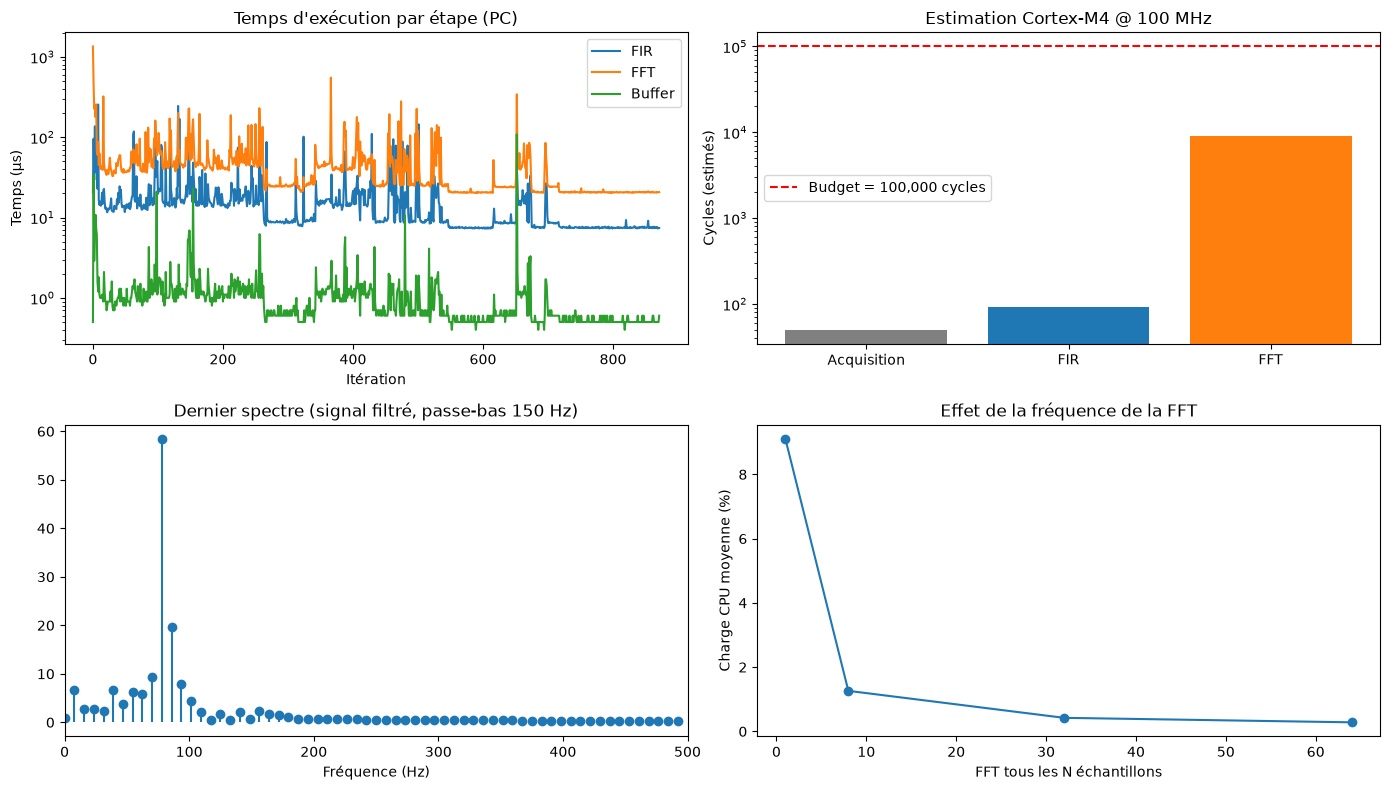

In [4]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ---------- Paramètres ----------
fs = 1000                 # Hz -> période d'échantillonnage Te = 1 ms
N_BUF, N_TAPS, N_FFT = 128, 31, 128
N_ITER = 1000
b = signal.firwin(N_TAPS, 150, fs=fs, window='hamming')

np.random.seed(0)
t_all = np.arange(N_ITER) / fs
entree = np.sin(2*np.pi*80*t_all) + 0.5*np.sin(2*np.pi*250*t_all) + 0.3*np.random.randn(N_ITER)

def simuler(hop_fft):
    """Traitement continu. hop_fft = nombre d'échantillons entre deux FFT (1 = à chaque itération)."""
    buf_in = np.zeros(N_BUF)            # buffer circulaire d'entrée
    buf_out = np.zeros(N_BUF)           # buffer circulaire des échantillons filtrés
    idx = 0                             # position d'écriture
    t_buf, t_fir, t_fft = [], [], []
    spectre = None
    for n in range(N_ITER):
        # 1) Acquisition + mise à jour du buffer circulaire (O(1), sans np.roll)
        t0 = time.perf_counter()
        buf_in[idx] = entree[n]
        t1 = time.perf_counter()
        # 2) Filtre FIR sur les 31 derniers échantillons (ordre chronologique inversé)
        dernier = buf_in[(idx - np.arange(N_TAPS)) % N_BUF]
        buf_out[idx] = np.dot(b, dernier)
        t2 = time.perf_counter()
        # 3) FFT sur les 128 derniers échantillons filtrés (périodique)
        if n >= N_BUF and n % hop_fft == 0:
            fenetre = buf_out[(idx + 1 + np.arange(N_BUF)) % N_BUF]    # remise en ordre chronologique
            spectre = np.abs(np.fft.fft(fenetre, N_FFT)[:N_FFT//2])
            t3 = time.perf_counter()
            t_fft.append(t3 - t2)
        t_buf.append(t1 - t0); t_fir.append(t2 - t1)
        idx = (idx + 1) % N_BUF
    return np.array(t_buf), np.array(t_fir), np.array(t_fft), spectre

# ---------- 2) Mesures (FFT à chaque échantillon) ----------
t_buf, t_fir, t_fft, spectre = simuler(hop_fft=1)
us = 1e6
print(f"{'Étape':<22}{'moyenne (µs)':>14}{'max (µs)':>12}")
for nom, tt in (("Buffer circulaire", t_buf), ("Filtre FIR (31)", t_fir), ("FFT 128 points", t_fft)):
    print(f"{nom:<22}{tt.mean()*us:>14.2f}{tt.max()*us:>12.2f}")
print(f"Total par échantillon : {(t_buf.mean()+t_fir.mean()+t_fft.mean())*us:.1f} µs (sur le PC, pour comparer les étapes entre elles)")

# ---------- 3) Estimation sur Cortex-M4 @ 100 MHz (nombre de cycles) ----------
f_cpu = 100e6
budget = f_cpu / fs                                   # cycles disponibles par échantillon
cyc_mac_fir = 2                                       # hypothèse : ~2 cycles/MAC (DSP M4, q15, SIMD ou boucle simple)
cyc_fir = N_TAPS * cyc_mac_fir + 30                   # + surcoût de la boucle/appel
n_papillons = (N_FFT // 2) * int(np.log2(N_FFT))      # 64 * 7 = 448 papillons radix-2
cyc_papillon = 20                                     # hypothèse : ~20 cycles par papillon complexe en q15
cyc_fft = n_papillons * cyc_papillon
cyc_acq = 50                                          # lecture ADC + écriture buffer (hypothèse)
cyc_total = cyc_acq + cyc_fir + cyc_fft
print(f"\nBudget : {budget:,.0f} cycles par échantillon (Te = 1 ms à {f_cpu/1e6:.0f} MHz)")
print(f"FIR  ≈ {cyc_fir:>7,.0f} cycles")
print(f"FFT  ≈ {cyc_fft:>7,.0f} cycles ({n_papillons} papillons)")
print(f"Total ≈ {cyc_total:>6,.0f} cycles = {cyc_total/f_cpu*1e6:.0f} µs -> charge CPU ≈ {100*cyc_total/budget:.0f} %")
print("Faisable :", cyc_total < budget)

# ---------- 4) Optimisation : FFT tous les N échantillons ----------
res = {}
for hop in (1, 8, 32, 64):
    tb, tf, tfft, _ = simuler(hop)
    par_echantillon = tb.mean() + tf.mean() + (tfft.sum() / N_ITER)
    cyc_moy = cyc_acq + cyc_fir + cyc_fft / hop
    res[hop] = (par_echantillon*us, cyc_moy)
    print(f"FFT tous les {hop:>2} éch. : PC = {par_echantillon*us:6.1f} µs/éch. | M4 ≈ {cyc_moy:7,.0f} cycles/éch. "
          f"(charge moyenne {100*cyc_moy/budget:.1f} %)")

# ---------- Tracés ----------
plt.figure(figsize=(14, 8))
plt.subplot(2, 2, 1)
plt.plot(t_fir[N_BUF:]*us, label='FIR'); plt.plot(t_fft*us, label='FFT'); plt.plot(t_buf[N_BUF:]*us, label='Buffer')
plt.yscale('log'); plt.xlabel('Itération'); plt.ylabel('Temps (µs)'); plt.title('Temps d\'exécution par étape (PC)'); plt.legend()

plt.subplot(2, 2, 2)
plt.bar(['Acquisition', 'FIR', 'FFT'], [cyc_acq, cyc_fir, cyc_fft], color=['gray', 'tab:blue', 'tab:orange'])
plt.axhline(budget, color='r', ls='--', label=f'Budget = {budget:,.0f} cycles'); plt.yscale('log')
plt.ylabel('Cycles (estimés)'); plt.title('Estimation Cortex-M4 @ 100 MHz'); plt.legend()

plt.subplot(2, 2, 3)
plt.stem(np.arange(N_FFT//2) * fs / N_FFT, spectre, basefmt=' ')
plt.xlim(0, 500); plt.xlabel('Fréquence (Hz)'); plt.title('Dernier spectre (signal filtré, passe-bas 150 Hz)')

plt.subplot(2, 2, 4)
hops = list(res.keys())
plt.plot(hops, [100*res[h][1]/budget for h in hops], 'o-')
plt.xlabel('FFT tous les N échantillons'); plt.ylabel('Charge CPU moyenne (%)'); plt.title('Effet de la fréquence de la FFT')
plt.tight_layout(); plt.show()

In [ ]:
# À compléter
# Exemple de structure
import time

buffer_size = 128
buffer = np.zeros(buffer_size)

# Simulation de l'acquisition
for n in range(200):
    # Nouvel échantillon (simulé)
    new_sample = np.random.randn()
    # Mise à jour du buffer circulaire
    buffer = np.roll(buffer, -1)
    buffer[-1] = new_sample
    # Filtrage (si n > taille filtre)
    # FFT (périodique)
    pass


# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---